# ARTI 403 — Image Processing
## Lab 3 — Image Manipulations using OpenCV Library

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Image Manipulations using OpenCV Library |
| **Session No.** | 3 |
| **Duration** | 150 minutes |
| **Student name** | Abdulrahman Saleh Alaamri |
| **Student ID** | 2240002427 |

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Load the image

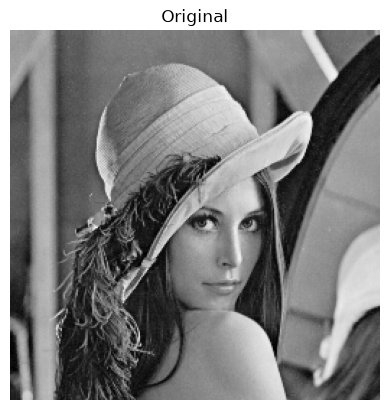

In [2]:
img = cv2.imread('../images/lena_gray_256.tif', cv2.IMREAD_GRAYSCALE)
h, w = img.shape

plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')
plt.show()

## Task 1: Geometric Transformations

### 1. Increase the size of the image

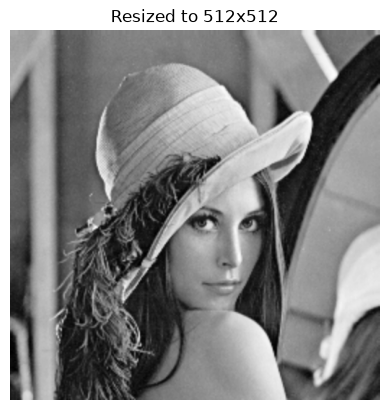

True

In [3]:
bigger = cv2.resize(img, (w * 2, h * 2), interpolation=cv2.INTER_LINEAR)

plt.imshow(bigger, cmap='gray')
plt.title(f'Resized to {bigger.shape[1]}x{bigger.shape[0]}')
plt.axis('off')
plt.show()

cv2.imwrite('output/resized.jpg', bigger)

### 2. Rotate the image by 120 degrees

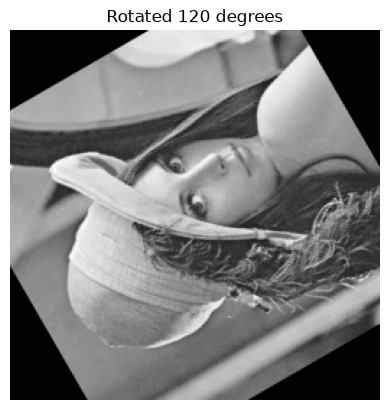

True

In [4]:
center = (w // 2, h // 2)
M_rotate = cv2.getRotationMatrix2D(center, 120, 1.0)
rotated = cv2.warpAffine(img, M_rotate, (w, h))

plt.imshow(rotated, cmap='gray')
plt.title('Rotated 120 degrees')
plt.axis('off')
plt.show()

cv2.imwrite('output/rotated.jpg', rotated)

### 3. Shear operation

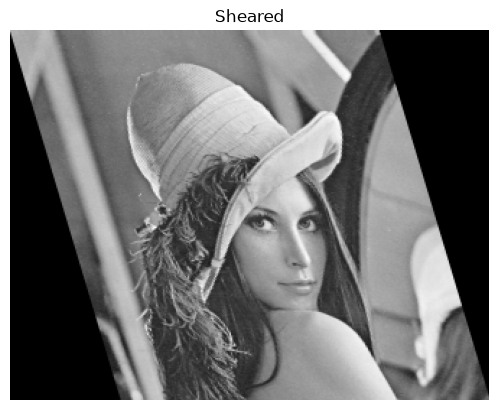

True

In [5]:
M_shear = np.float32([[1, 0.3, 0],
                      [0, 1, 0]])
sheared = cv2.warpAffine(img, M_shear, (int(w * 1.3), h))

plt.imshow(sheared, cmap='gray')
plt.title('Sheared')
plt.axis('off')
plt.show()

cv2.imwrite('output/sheared.jpg', sheared)

## Task 2: Intensity Transformations

### 1. Negative image

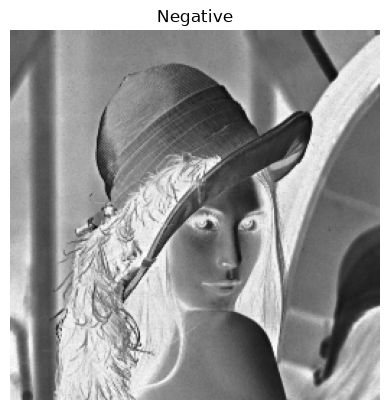

True

In [6]:
negative = 255 - img

plt.imshow(negative, cmap='gray')
plt.title('Negative')
plt.axis('off')
plt.show()

cv2.imwrite('output/negative.jpg', negative)

### 2. Log transform

`c` is picked so the max output stays at 255.

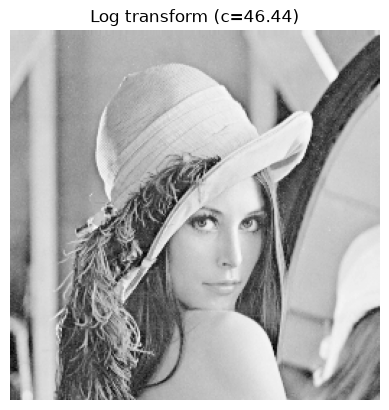

True

In [7]:
c = 255 / np.log(1 + np.max(img))
log_img = c * np.log(1 + img.astype(np.float64))
log_img = log_img.astype(np.uint8)

plt.imshow(log_img, cmap='gray')
plt.title(f'Log transform (c={c:.2f})')
plt.axis('off')
plt.show()

cv2.imwrite('output/log.jpg', log_img)

### 3. Power law (gamma) transform

`gamma > 1` darkens the mid-tones and increases contrast.

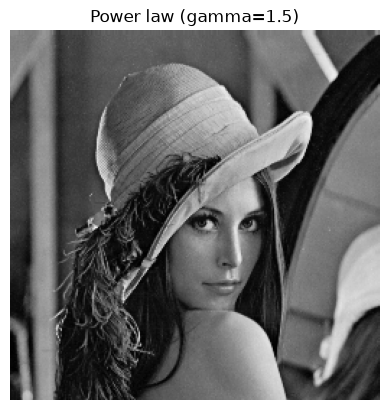

True

In [8]:
gamma = 1.5
power_img = 255 * (img / 255) ** gamma
power_img = power_img.astype(np.uint8)

plt.imshow(power_img, cmap='gray')
plt.title(f'Power law (gamma={gamma})')
plt.axis('off')
plt.show()

cv2.imwrite('output/power_law.jpg', power_img)